<center><h1>Batra_Raghav_HW5</h1></center>
<br>
<br>

Name: Raghav Batra
<br>
Github Username: rbatra02
<br>
USC ID: 3227519293

## 1. Decision Trees as Interpretable Models

Import packages

In [59]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error
from xgboost import XGBRegressor
np.random.seed(0)

### (a) Obtain Data

Get the Accute Inamations Data Set

In [60]:
cols = ['temperature', 'nausea', 'lumbar_pain', 'urine_pushing', 'micturition_pains',
        'burning_urethra', 'inflammation_bladder', 'nephritis']
acute = pd.read_csv("../acute+inflammations/diagnosis.data", sep='\t', header=None,
                    names=cols, encoding='utf-16', decimal=',')
for c in cols[1:]:
    acute[c] = (acute[c].str.strip() == 'yes').astype(int)
print(acute.shape)
acute.head()

(120, 8)


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pains,burning_urethra,inflammation_bladder,nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

Yes the labeled powerset is more relevant. The two diagnoses co-occur and all 4 combinations appear in the data, so one tree models them jointly. Binary relevance would ignore that dependence.

bladder      40
nephritis    31
none         30
both         19
Name: count, dtype: int64
depth 4 leaves 6 train acc 1.0


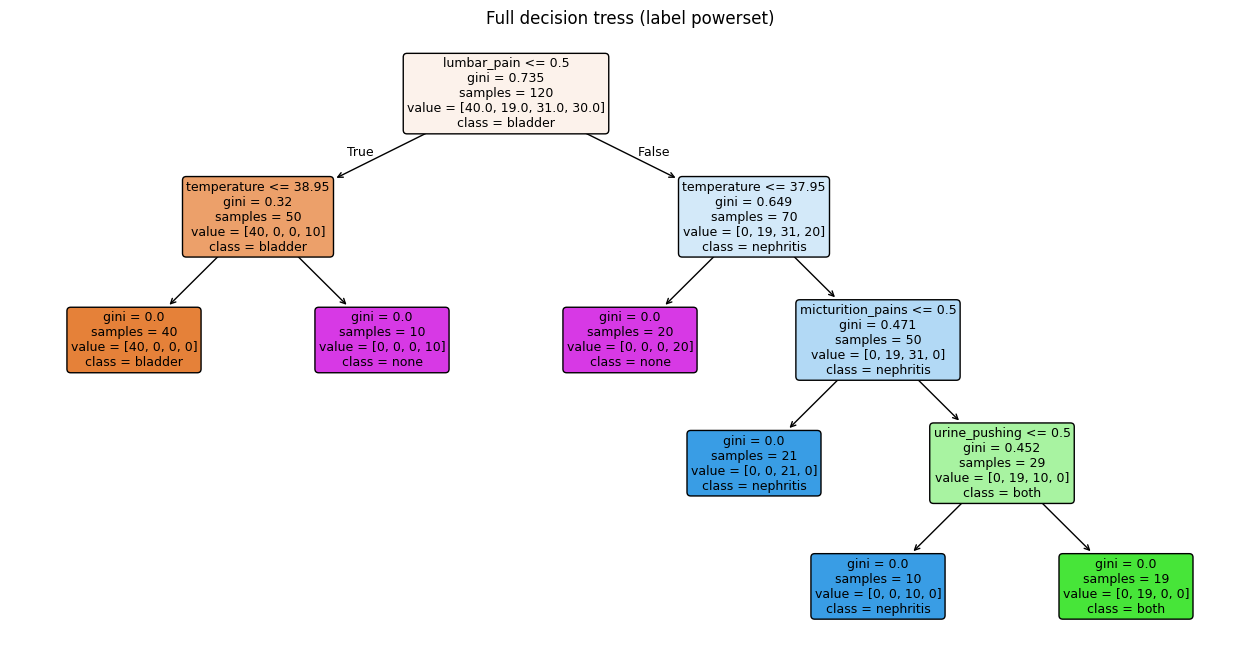

In [61]:
X1 = acute[cols[:6]]
labels = {(0,0): 'none', (1,0): 'bladder', (0,1): 'nephritis', (1,1): 'both'}
y1 = acute[['inflammation_bladder', 'nephritis']].apply(lambda r: labels[tuple(r)], axis=1)
print(y1.value_counts())
tree = DecisionTreeClassifier(random_state=0).fit(X1, y1)
print('depth', tree.get_depth(), 'leaves', tree.get_n_leaves(), 'train acc', tree.score(X1, y1))
plt.figure(figsize=(16,8))
plot_tree(tree, feature_names=X1.columns, class_names=tree.classes_, filled=True, rounded=True, fontsize=9)
plt.title('Full decision tress (label powerset)')
plt.show()

### (c) Convert the decision rules

In [62]:
def tree_to_rules(clf, feat):
    t = clf.tree_
    rules = []
    def rec (node, conds):
        if t.feature[node] < 0:
            cls = clf.classes_[np.argmax(t.value[node])]
            rules.append(f"IF {' AND '.join(conds) or 'TRUE'} THEN diagnosis = {cls}   (n={int(t.n_node_samples[node])})")
            return
        f,th= feat[t.feature[node]], t.threshold[node]
        rec(t.children_left[node], conds + [f"{f} <= {th:.2f}"])
        rec(t.children_right[node], conds + [f"{f} > {th:.2f}"])
    rec(0,[])
    return rules
for r in tree_to_rules(tree, list(X1.columns)):
    print(r)

IF lumbar_pain <= 0.50 AND temperature <= 38.95 THEN diagnosis = bladder   (n=40)
IF lumbar_pain <= 0.50 AND temperature > 38.95 THEN diagnosis = none   (n=10)
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN diagnosis = none   (n=20)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN diagnosis = nephritis   (n=21)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN diagnosis = nephritis   (n=10)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN diagnosis = both   (n=19)


d) Cost-complexity pruning

      alpha    cv_acc  leaves
0  0.000000  0.991667       6
1  0.098167  0.858333       4
2  0.133333  0.758333       3
3  0.182000  0.683333       2
4  0.222917  0.483333       1
chosen alpha 0.0 leaves 6 train_acc 1.0


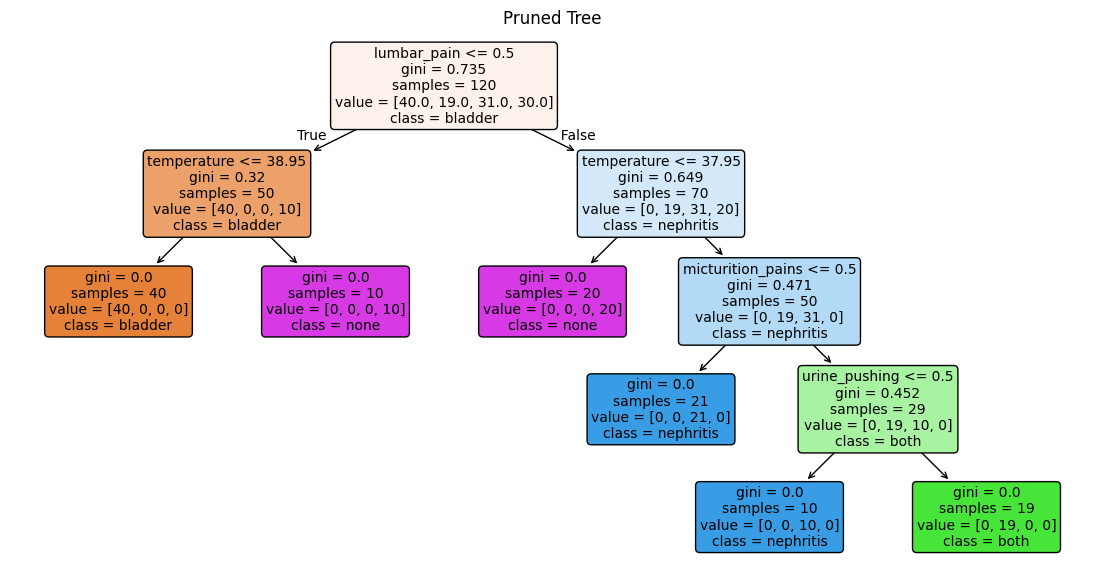

IF lumbar_pain <= 0.50 AND temperature <= 38.95 THEN diagnosis = bladder   (n=40)
IF lumbar_pain <= 0.50 AND temperature > 38.95 THEN diagnosis = none   (n=10)
IF lumbar_pain > 0.50 AND temperature <= 37.95 THEN diagnosis = none   (n=20)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains <= 0.50 THEN diagnosis = nephritis   (n=21)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing <= 0.50 THEN diagnosis = nephritis   (n=10)
IF lumbar_pain > 0.50 AND temperature > 37.95 AND micturition_pains > 0.50 AND urine_pushing > 0.50 THEN diagnosis = both   (n=19)


In [63]:
path = tree.cost_complexity_pruning_path(X1,y1)
alphas = np.unique(path.ccp_alphas)
skf = StratifiedKFold(5, shuffle=True, random_state=0)
res = []
for a in alphas: 
    m = DecisionTreeClassifier(random_state=0, ccp_alpha=a)
    acc = cross_val_score(m, X1, y1, cv=skf).mean()
    leaves = m.fit(X1, y1).get_n_leaves()
    res.append((a,acc,leaves))

res =pd.DataFrame(res, columns=['alpha', 'cv_acc', 'leaves'])
print(res)

best_alpha = res[res.cv_acc >= res.cv_acc.max() - 1e-9].alpha.max()
pruned = DecisionTreeClassifier(random_state=0, ccp_alpha=best_alpha).fit(X1,y1)
print('chosen alpha', best_alpha, 'leaves', pruned.get_n_leaves(), 'train_acc', pruned.score(X1,y1))
plt.figure(figsize=(14,7))
plot_tree(pruned, feature_names=X1.columns, class_names=pruned.classes_, filled=True, rounded=True, fontsize=10)
plt.title('Pruned Tree')
plt.show()
for r in tree_to_rules(pruned, list(X1.columns)):
    print(r)

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [64]:
names = [line.split()[1] for line in open("../Homework 5 Data/communities.names") if line.startswith('@attribute')]
crime = pd.read_csv("../Homework 5 Data/communities.data", header=None, names=names, na_values='?')
train, test = crime.iloc[:1495], crime.iloc[1495:]
print(crime.shape, train.shape, test.shape)
crime.head()

(1994, 128) (1495, 128) (499, 128)


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values


drop 5 nonpredictive cols [state, county, community, communityname, fold] and remaining missing values replace with training set median

In [65]:
cc = crime.drop(columns=['state', 'county', 'community', 'communityname', 'fold'])
target = 'ViolentCrimesPerPop'
train, test = cc.iloc[:1495].copy(), cc.iloc[1495:].copy()
med = train.median()
print('cols with missing: ', int((cc.isna().sum()>0).sum()))
train,test = train.fillna(med), test.fillna(med)
Xtr, ytr = train.drop(columns=target), train[target]
Xte, yte = test.drop(columns=target), test[target]
print(Xtr.shape, Xte.shape)

cols with missing:  23
(1495, 122) (499, 122)


### (c) Plot a correlation matrix

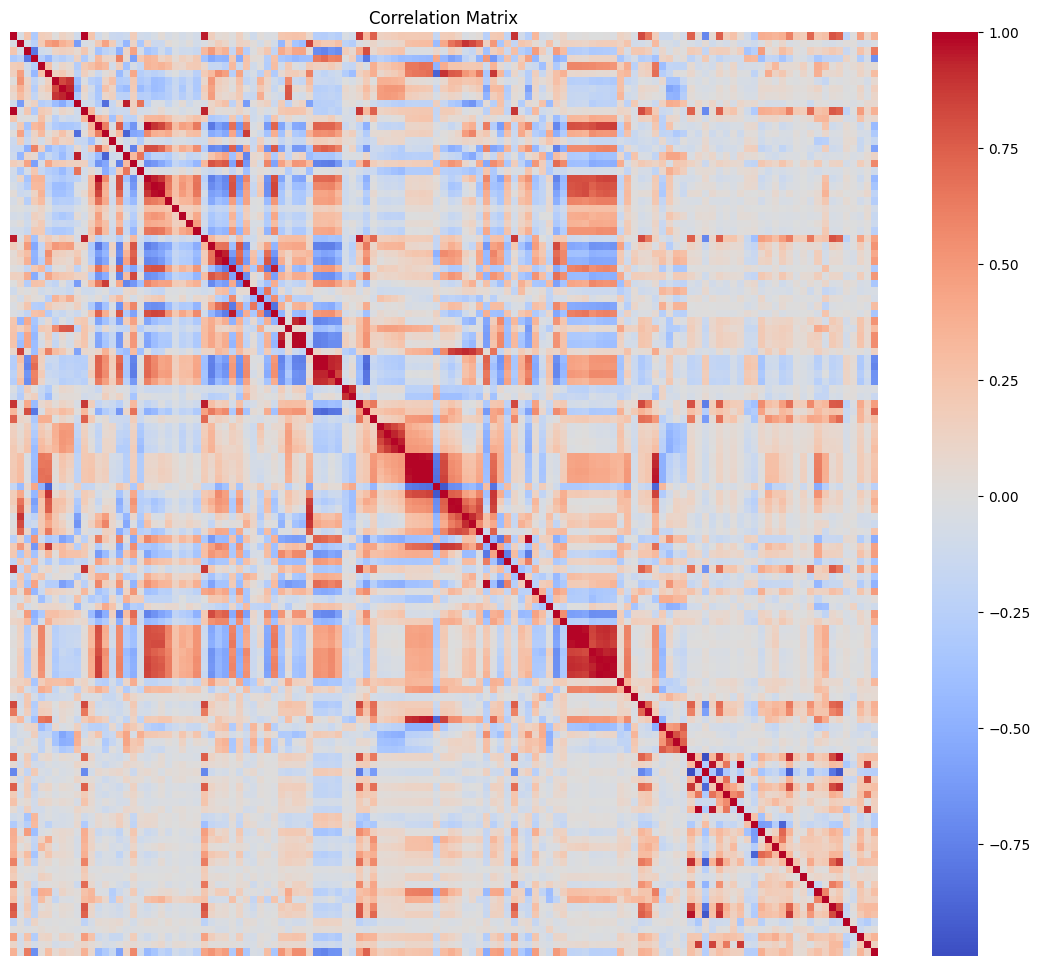

In [66]:
full = pd.concat([train, test])
plt.figure(figsize=(14,12))
sns.heatmap(full.corr(), cmap='coolwarm', center=0, xticklabels=False, yticklabels=False)
plt.title('Correlation Matrix')
plt.show()

### (d) Calculate the Coefficient of Variation CV

In [67]:
Xall = full.drop(columns=target)
cv = (Xall.std(ddof=1) / Xall.mean()).sort_values(ascending=False)
cv.to_frame('CV')

,CV
PctPolicAsian,5.447835
NumStreet,4.407702
NumInShelters,3.485481
NumIlleg,2.994196
NumImmig,2.900497
...,...
NumKindsDrugsSeiz,0.143227
RacialMatchCommPol,0.126902
LemasPctPolicOnPatr,0.117807
PctPolicWhite,0.117726


### (e) Scatter plots and box plots for highest CV features

['PctPolicAsian', 'NumStreet', 'NumInShelters', 'NumIlleg', 'NumImmig', 'LemasPctOfficDrugUn', 'NumUnderPov', 'population', 'LemasSwornFT', 'numbUrban', 'HousVacant']


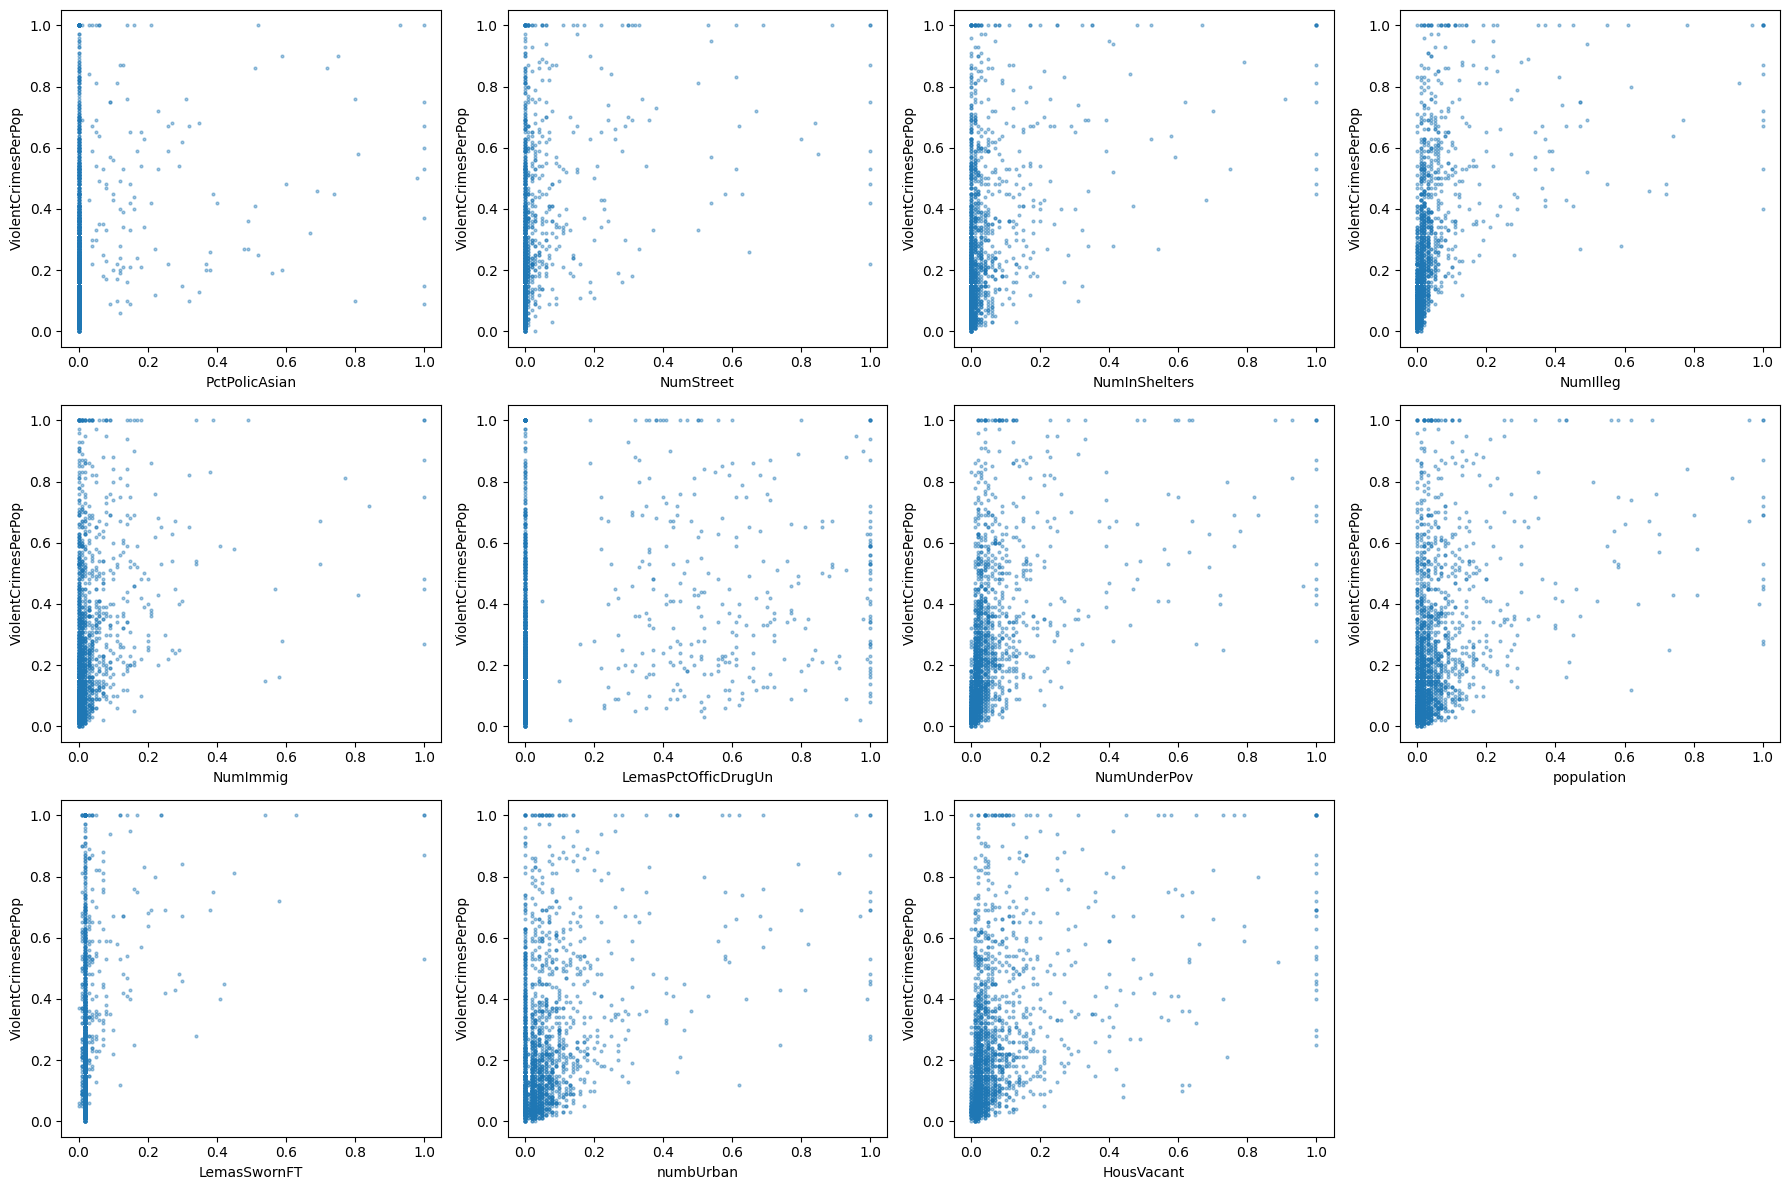

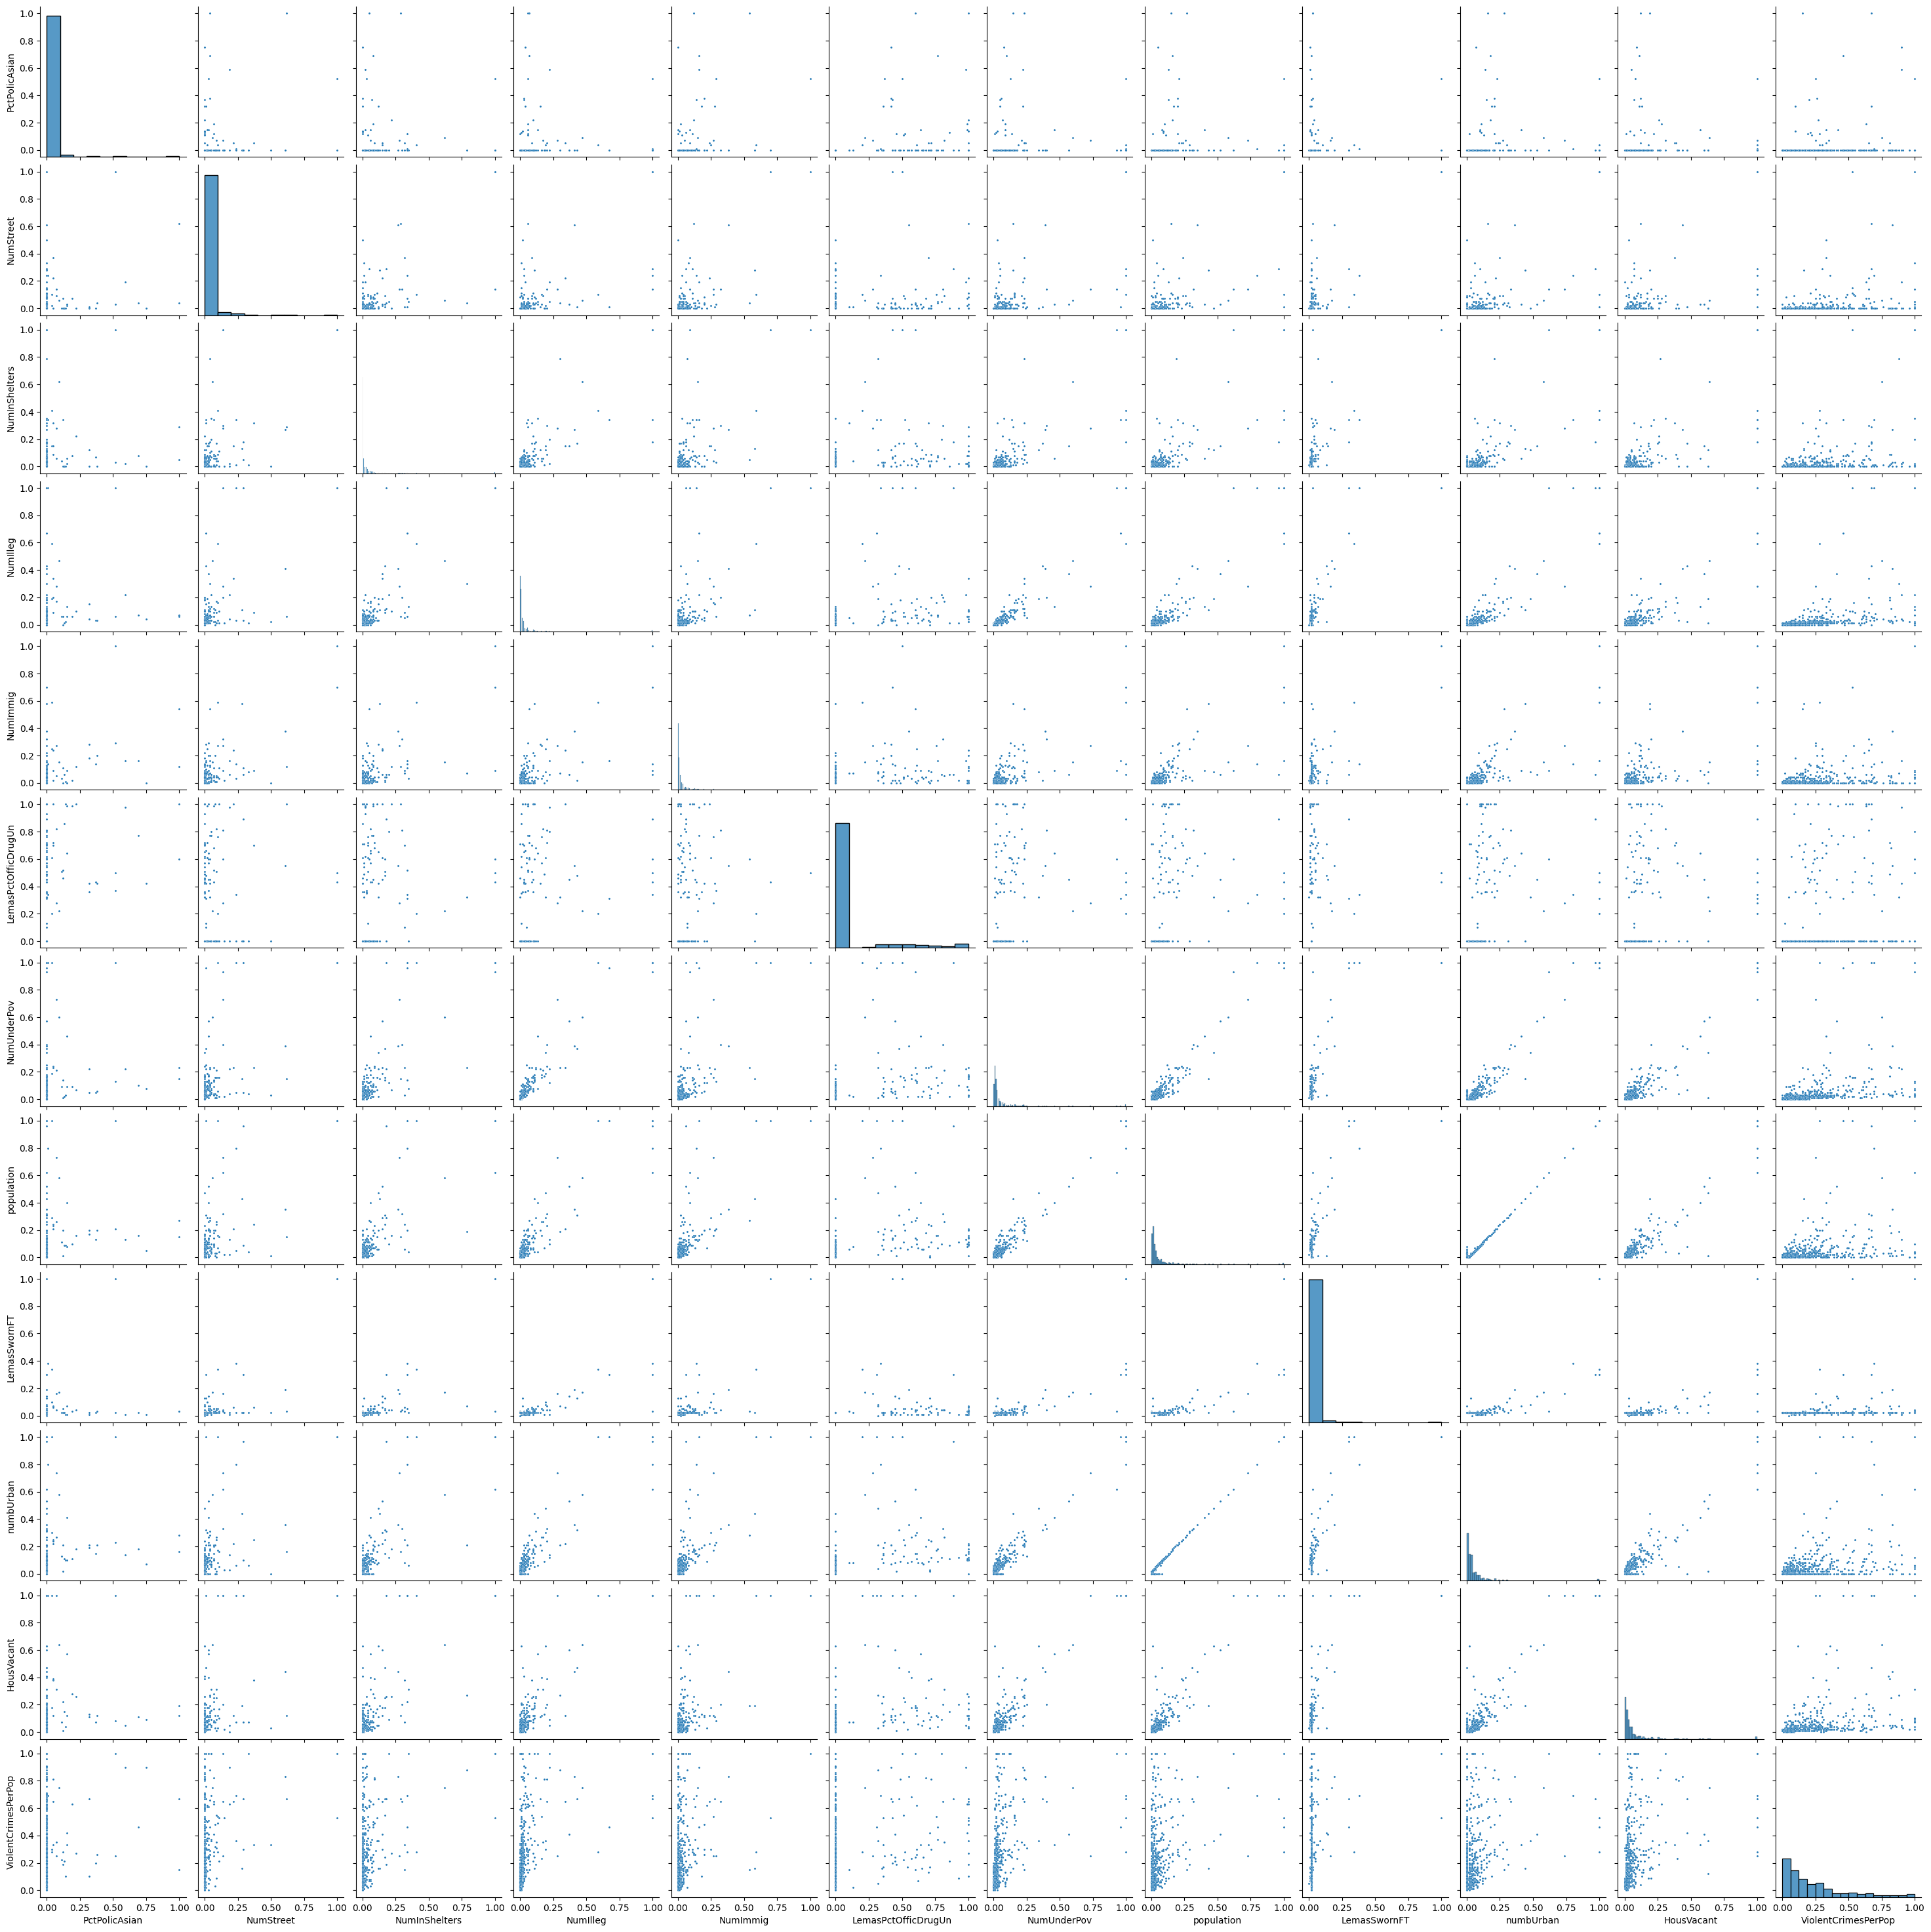

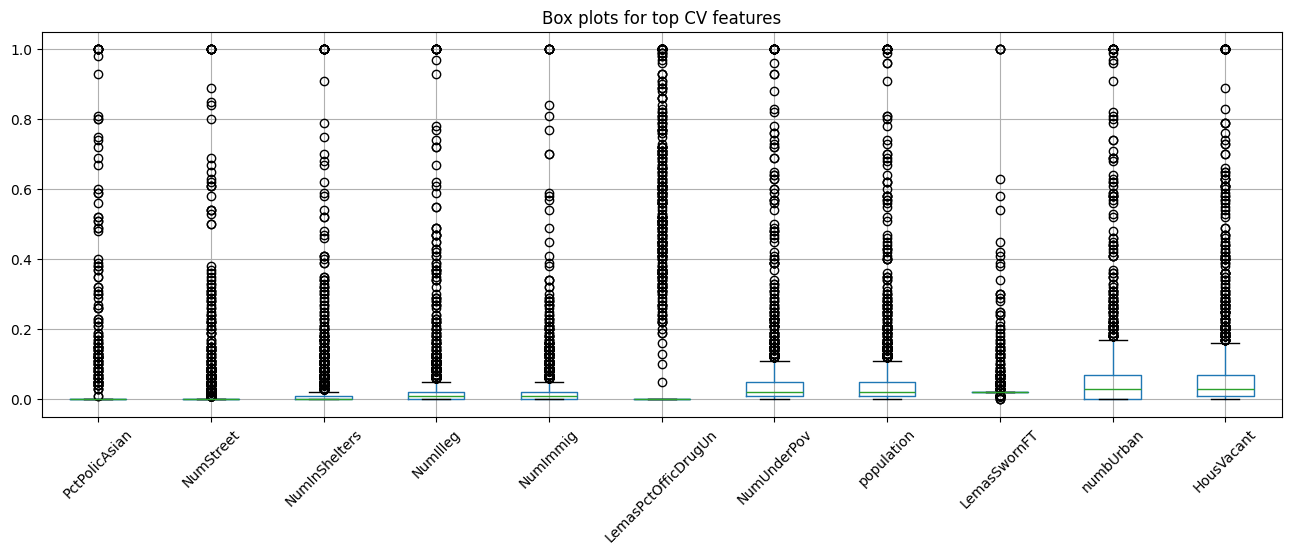

PctPolicAsian          0.20
NumStreet              0.34
NumInShelters          0.38
NumIlleg               0.47
NumImmig               0.29
LemasPctOfficDrugUn    0.35
NumUnderPov            0.45
population             0.37
LemasSwornFT           0.27
numbUrban              0.36
HousVacant             0.42
ViolentCrimesPerPop    1.00
Name: ViolentCrimesPerPop, dtype: float64


In [68]:
k=int(np.floor(np.sqrt(128)))
top = cv.index[:k].tolist()
print(top)
fig, axes = plt.subplots(3,4, figsize=(18,12))
for ax, f in zip(axes.flat, top):
    ax.scatter(full[f], full[target], s=4, alpha=0.4)
    ax.set_xlabel(f)
    ax.set_ylabel(target)
axes.flat[-1].axis('off')
plt.tight_layout()
plt.show()

sns.pairplot(full[top + [target]].sample(500, random_state=0), plot_kws={'s': 5})
plt.show()
plt.figure(figsize=(16,5))
full[top].boxplot(rot=45)
plt.title('Box plots for top CV features')
plt.show()
print(full[top + [target]].corr()[target].round(2))


No you cannot judge significance from the scatter plots alone as most of the features are heavily skewed, with nearly all points piled near 0 and a few outliers.

### (f) Fit a linear model

In [69]:
ols = LinearRegression().fit(Xtr, ytr)
results = {'OLS': mean_squared_error(yte, ols.predict(Xte))}
print(f"Test MSE: {results['OLS']:.4f}")

Test MSE: 0.0180


### (g) Fit a ridge regression model

In [70]:
kf = KFold(10, shuffle=True, random_state=0)
ridge= RidgeCV(alphas=np.logspace(-4, 4, 50), cv=kf).fit(Xtr, ytr)
results['Ridge'] = mean_squared_error(yte, ridge.predict(Xte))
print(f"lambba: {ridge.alpha_:.4f}, Test MSE: {results['Ridge']:.4f}")

lambba: 2.5595, Test MSE: 0.0175


### (h) Fit a LASSO model

In [71]:
lasso = LassoCV(cv=kf, n_alphas=200, max_iter=50000, random_state=0).fit(Xtr, ytr)
results['Lasso'] = mean_squared_error(yte, lasso.predict(Xte))
sel = Xtr.columns[lasso.coef_ != 0]
print(f"lambda, {lasso.alpha_:.2e}, Test MSE, {results['Lasso']:.4f}")
print(list(sel))

sc = StandardScaler().fit(Xtr)
lasso_s = LassoCV(cv=kf, n_alphas=200, max_iter=50000, random_state=0).fit(sc.transform(Xtr), ytr)
results["Standardized Lasso"] = mean_squared_error(yte, lasso_s.predict(sc.transform(Xte)))
sel_s = Xtr.columns[lasso_s.coef_ != 0]
print(f"lambda, {lasso_s.alpha_:.2e}, Test MSE, {results['Standardized Lasso']:.4f}")
print(list(sel_s))

lambda, 9.06e-05, Test MSE, 0.0177
['racepctblack', 'racePctAsian', 'agePct12t21', 'agePct12t29', 'agePct65up', 'pctUrban', 'pctWWage', 'pctWFarmSelf', 'pctWInvInc', 'pctWSocSec', 'pctWPubAsst', 'pctWRetire', 'whitePerCap', 'blackPerCap', 'indianPerCap', 'AsianPerCap', 'OtherPerCap', 'HispPerCap', 'PctPopUnderPov', 'PctLess9thGrade', 'PctBSorMore', 'PctEmploy', 'PctEmplManu', 'PctOccupManu', 'MalePctDivorce', 'MalePctNevMarr', 'FemalePctDiv', 'PctKids2Par', 'PctYoungKids2Par', 'PctTeen2Par', 'PctWorkMom', 'NumIlleg', 'PctIlleg', 'NumImmig', 'PctImmigRec10', 'PctRecImmig10', 'PctNotSpeakEnglWell', 'PctLargHouseOccup', 'PersPerOccupHous', 'PersPerOwnOccHous', 'PctPersOwnOccup', 'PctPersDenseHous', 'PctHousLess3BR', 'MedNumBR', 'HousVacant', 'PctHousOccup', 'PctVacantBoarded', 'PctVacMore6Mos', 'MedYrHousBuilt', 'PctHousNoPhone', 'PctWOFullPlumb', 'OwnOccLowQuart', 'RentLowQ', 'MedRent', 'MedRentPctHousInc', 'MedOwnCostPctInc', 'MedOwnCostPctIncNoMtg', 'NumInShelters', 'NumStreet', 'PctFo

Raw and standardized give roughly the same MSE of .0177 because the features are normalized between [0,1].

### (i) Fit a PCR model

M = 95 Test MSE 0.018296345367709792


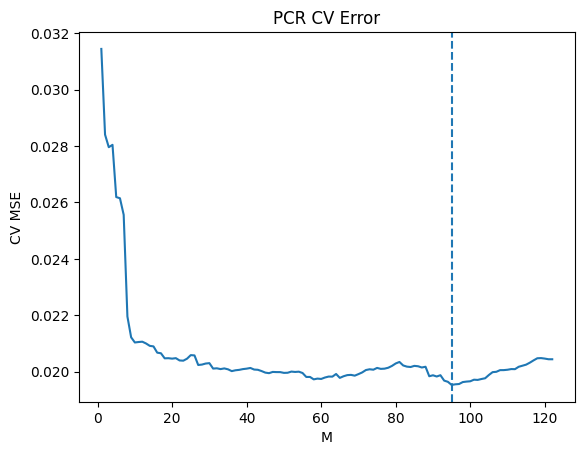

In [72]:
pcr = Pipeline([('sc', StandardScaler()), ('pca', PCA()), ('lr', LinearRegression())])
gs = GridSearchCV(pcr, {'pca__n_components': range(1, Xtr.shape[1] + 1)}, cv=kf, scoring='neg_mean_squared_error').fit(Xtr,ytr)
M = gs.best_params_['pca__n_components']
results['PCR'] = mean_squared_error(yte, gs.predict(Xte))
print('M =', M, 'Test MSE', results['PCR'])
plt.plot(range(1, Xtr.shape[1] + 1), -gs.cv_results_['mean_test_score'])
plt.axvline(M, ls="--")
plt.xlabel('M')
plt.ylabel('CV MSE')
plt.title('PCR CV Error')
plt.show()

### (j) Fit a boosting tree

In [73]:
xgb = XGBRegressor(n_estimators=300, learning_rate=.05, max_depth=3, subsample=.8, 
                   colsample_bytree=.8, random_state=0, n_jobs=-1)
gx = GridSearchCV(xgb, {'reg_alpha': [0,1e-3,1e-2,.05,.1,.5,1,5,10]}, cv=kf, scoring='neg_mean_squared_error').fit(Xtr, ytr)
results['XGBoost L1'] = mean_squared_error(yte, gx.predict(Xte))
print('alpha', gx.best_params_['reg_alpha'], 'Test MSE', results['XGBoost L1'])


pd.Series(results, name='Test MSE').sort_values().to_frame()

alpha 1 Test MSE 0.01593383364722521


,Test MSE
XGBoost L1,0.015934
Ridge,0.017504
Lasso,0.017676
Standardized Lasso,0.017721
OLS,0.017966
PCR,0.018296
